# Imports

In [2]:
import pandas as pd
import numpy as np
import json
import joblib
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import os
import sys

from policy_preprocessor_pipeline import PolicyPreprocessor
pd.set_option("display.max_columns", 200)

# Loading data

In [3]:
df = pd.read_parquet("../ai_logs (1).parquet")
print(f"Total rows: {len(df)}")
print(f"Columns: {df.columns.tolist()}")


Total rows: 11940
Columns: ['id', 'session_id', 'player_mark', 'board', 'legal_moves', 'ai_move', 'game_status', 'timestamp', 'mcts_iterations', 'exploration_constant', 'visit_counts_json', 'action_scores_json', 'policy_vector_json', 'best_visit_count', 'best_q_value', 'move_confidence', 'branching_factor', 'explored_actions', 'mcts_tree_size', 'rollout_count', 'rollout_depth_avg', 'rollout_depth_max', 'mcts_search_duration_ms', 'ai_latency_ms', 'ai_difficulty', 'gm_suggested_move', 'move_matches_gm', 'gm_mcts_iterations', 'gm_exploration_constant', 'gm_visit_counts_json', 'gm_action_scores_json', 'gm_policy_vector_json', 'gm_best_visit_count', 'gm_best_q_value', 'gm_move_confidence', 'gm_explored_actions', 'gm_mcts_tree_size', 'gm_mcts_search_duration_ms', 'final_result']


In [4]:
# Check for missing GM data
print("\nMissing GM data:")
print(df[['gm_policy_vector_json', 'gm_best_q_value']].isnull().sum())


Missing GM data:
gm_policy_vector_json    0
gm_best_q_value          0
dtype: int64


In [5]:
# Drop rows without GM data
df_clean = df.dropna(subset=['gm_policy_vector_json', 'gm_best_q_value'])
print(f"\nRows after cleaning: {len(df_clean)}")



Rows after cleaning: 11940


# Data augmentation (flipping the board in different angles to create more possibilities, flipping the policy vector to match the board)

In [6]:
# ============================================================
# SYMMETRY AUGMENTATION FOR TIC-TAC-TOE
# ============================================================

def symmetries():
    return [
        lambda r, c: (r, c),               # identity
        lambda r, c: (c, 2 - r),           # rotate 90
        lambda r, c: (2 - r, 2 - c),       # rotate 180
        lambda r, c: (2 - c, r),           # rotate 270
        lambda r, c: (r, 2 - c),           # mirror horizontal
        lambda r, c: (2 - r, c),           # mirror vertical
        lambda r, c: (c, r),               # main diagonal
        lambda r, c: (2 - c, 2 - r),       # anti-diagonal
    ]


def transform_board(board, transform):
    new_board = [["" for _ in range(3)] for _ in range(3)]
    for r in range(3):
        for c in range(3):
            nr, nc = transform(r, c)
            new_board[nr][nc] = board[r][c]
    return new_board


def transform_policy(policy, transform):
    new_policy = np.zeros(9, dtype=np.float32)
    for r in range(3):
        for c in range(3):
            idx = r * 3 + c
            nr, nc = transform(r, c)
            new_idx = nr * 3 + nc
            new_policy[new_idx] = policy[idx]
    return new_policy

def augment_with_symmetry(df, X, y, preprocessor):
    X_aug = []
    y_aug = []

    for i in range(len(X)):
        board = json.loads(df.iloc[i]["board"])
        player = df.iloc[i]["player_mark"]
        policy = y[i]

        for t in symmetries():
            board_t = transform_board(board, t)
            policy_t = transform_policy(policy, t)

            board_vec = preprocessor.encode_board(board_t, player)
            legal_vec = preprocessor.encode_legal_mask(board_t)
            x_t = np.concatenate([board_vec, legal_vec])

            X_aug.append(x_t)
            y_aug.append(policy_t)

    return np.array(X_aug), np.array(y_aug)


# Preprocessing the data and inspecting it

In [7]:
# Initialize preprocessor (try without metadata first for simplicity)
preprocessor = PolicyPreprocessor(use_gm_metadata=False)

# Transform dataset
X, y = preprocessor.transform_dataset(df_clean)

print("Before augmentation:", X.shape)

X, y = augment_with_symmetry(df_clean, X, y, preprocessor)

print("After augmentation:", X.shape)



Before augmentation: (11940, 18)
After augmentation: (95520, 18)


In [8]:
print(f"\nX shape: {X.shape}")  # Should be (N, 18) without metadata
print(f"y shape: {y.shape}")    # Should be (N, 9)
print(f"X features: {X.shape[1]}")



X shape: (95520, 18)
y shape: (95520, 9)
X features: 18


In [9]:
# Verify policy vectors are valid
print("\nSample policy vector:")
print(y[0])
print(f"Sum: {y[0].sum():.4f}")
print(f"Non-zero: {np.count_nonzero(y[0])}")
print(f"Max value: {y[0].max():.4f}")

# Check distribution
print(f"\nPolicy vector stats across dataset:")
print(f"Mean sum: {y.sum(axis=1).mean():.4f}")
print(f"Mean non-zero: {(y > 0).sum(axis=1).mean():.2f}")



Sample policy vector:
[0.1  0.03 0.1  0.07 0.36 0.05 0.15 0.03 0.11]
Sum: 1.0000
Non-zero: 9
Max value: 0.3600

Policy vector stats across dataset:
Mean sum: 1.0000
Mean non-zero: 6.05


In [10]:
# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, shuffle=True
)

print(f"\nTrain size: {X_train.shape[0]}")
print(f"Test size: {X_test.shape[0]}")


Train size: 76416
Test size: 19104


In [11]:
# Train MLP Regressor (predicts probability distribution)
from sklearn.neural_network import MLPRegressor

mlp_model = MLPRegressor(
    hidden_layer_sizes=(256, 128, 64),  # Deeper network
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    max_iter=1000,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=20,
    verbose=True
)

print("\nTraining model...")
mlp_model.fit(X_train, y_train)


Training model...
Iteration 1, loss = 0.01081629
Validation score: 0.617251
Iteration 2, loss = 0.00560433
Validation score: 0.752990
Iteration 3, loss = 0.00402079
Validation score: 0.807152
Iteration 4, loss = 0.00325852
Validation score: 0.834921
Iteration 5, loss = 0.00278937
Validation score: 0.853383
Iteration 6, loss = 0.00251784
Validation score: 0.871083
Iteration 7, loss = 0.00231398
Validation score: 0.879844
Iteration 8, loss = 0.00215562
Validation score: 0.883166
Iteration 9, loss = 0.00203784
Validation score: 0.888161
Iteration 10, loss = 0.00199772
Validation score: 0.894959
Iteration 11, loss = 0.00188303
Validation score: 0.900064
Iteration 12, loss = 0.00184584
Validation score: 0.903370
Iteration 13, loss = 0.00179954
Validation score: 0.900917
Iteration 14, loss = 0.00176515
Validation score: 0.904156
Iteration 15, loss = 0.00173319
Validation score: 0.906827
Iteration 16, loss = 0.00170859
Validation score: 0.910232
Iteration 17, loss = 0.00168642
Validation sco

D:\YEAR_3_integration_5\banditgames-ai\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:788: UserWarning: Training interrupted by user.
  warnings.warn("Training interrupted by user.")


,loss,'squared_error'
,hidden_layer_sizes,"(256, ...)"
,activation,'relu'
,solver,'adam'
,alpha,0.0001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,1000
,shuffle,True


In [12]:
# Predict on test set
mlp_pred = mlp_model.predict(X_test)

# Convert soft predictions to hard labels (argmax)
y_pred_argmax = np.argmax(mlp_pred, axis=1)
y_true_argmax = np.argmax(y_test, axis=1)

# Calculate accuracy
accuracy = accuracy_score(y_true_argmax, y_pred_argmax)
print(f"\n{'='*50}")
print(f"Argmax Accuracy: {accuracy:.4f}")
print(f"{'='*50}")




Argmax Accuracy: 0.8883


In [13]:
# Detailed evaluation
print("\nClassification Report:")
print(classification_report(y_true_argmax, y_pred_argmax))


# Top-k accuracy (is correct move in top 2/3 predictions?)
def top_k_accuracy(y_true, y_pred, k):
    top_k_pred = np.argsort(y_pred, axis=1)[:, -k:]
    correct = np.any(top_k_pred == y_true[:, None], axis=1)
    return correct.mean()


top2_acc = top_k_accuracy(y_true_argmax, mlp_pred, k=2)
top3_acc = top_k_accuracy(y_true_argmax, mlp_pred, k=3)

print(f"\nTop-2 Accuracy: {top2_acc:.4f}")
print(f"Top-3 Accuracy: {top3_acc:.4f}")


Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.81      0.85      2298
           1       0.98      0.75      0.85       907
           2       0.93      0.78      0.85      2212
           3       0.81      0.87      0.84       879
           4       0.96      0.98      0.97      7073
           5       0.80      0.81      0.80       749
           6       0.88      0.85      0.86      2119
           7       0.72      0.91      0.80       763
           8       0.74      0.90      0.82      2104

    accuracy                           0.89     19104
   macro avg       0.86      0.85      0.85     19104
weighted avg       0.90      0.89      0.89     19104


Top-2 Accuracy: 0.9647
Top-3 Accuracy: 0.9824


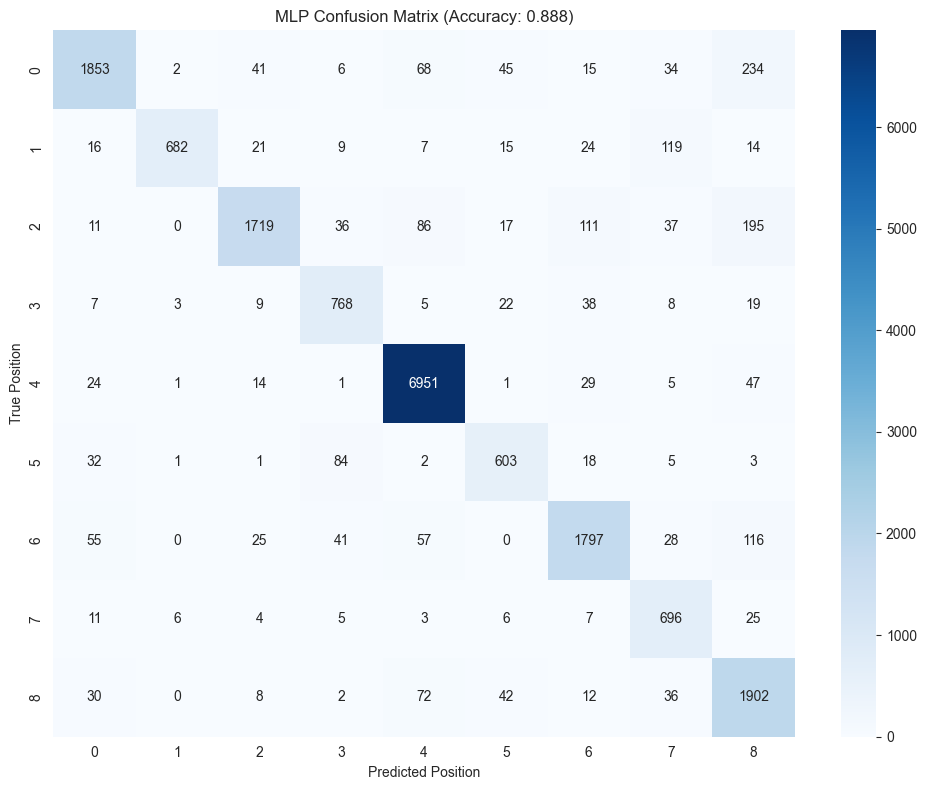

In [14]:
# Confusion matrix
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true_argmax, y_pred_argmax)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues")
plt.title(f"MLP Confusion Matrix (Accuracy: {accuracy:.3f})")
plt.xlabel("Predicted Position")
plt.ylabel("True Position")
plt.tight_layout()
plt.show()

In [15]:
# Analyze errors
errors = y_pred_argmax != y_true_argmax
print(f"\nTotal errors: {errors.sum()} / {len(errors)}")

# Show a few error cases
error_indices = np.where(errors)[0][:5]
for idx in error_indices:
    true_pos = y_true_argmax[idx]
    pred_pos = y_pred_argmax[idx]
    true_row, true_col = true_pos // 3, true_pos % 3
    pred_row, pred_col = pred_pos // 3, pred_pos % 3

    print(f"\nError example:")
    print(f"  True move: ({true_row}, {true_col}) [pos {true_pos}]")
    print(f"  Pred move: ({pred_row}, {pred_col}) [pos {pred_pos}]")
    print(f"  True prob: {y_test[idx][true_pos]:.3f}")
    print(f"  Pred prob: {mlp_pred[idx][pred_pos]:.3f}")



Total errors: 2133 / 19104

Error example:
  True move: (0, 2) [pos 2]
  Pred move: (2, 2) [pos 8]
  True prob: 0.210
  Pred prob: 0.208

Error example:
  True move: (0, 0) [pos 0]
  Pred move: (1, 2) [pos 5]
  True prob: 0.250
  Pred prob: 0.198

Error example:
  True move: (0, 1) [pos 1]
  Pred move: (2, 1) [pos 7]
  True prob: 0.710
  Pred prob: 0.405

Error example:
  True move: (0, 0) [pos 0]
  Pred move: (2, 2) [pos 8]
  True prob: 0.460
  Pred prob: 0.396

Error example:
  True move: (0, 2) [pos 2]
  Pred move: (2, 2) [pos 8]
  True prob: 0.240
  Pred prob: 0.208


In [25]:
# Save model and preprocessor
joblib.dump(mlp_model, "policy_model.pkl")
joblib.dump(preprocessor, "policy_preprocessor.pkl")

print("\n✓ Model and preprocessor saved successfully!")


✓ Model and preprocessor saved successfully!


# OPTIONAL WITH GM METADATA

In [22]:
# # Optional: Try with GM metadata
# print("\n" + "="*50)
# print("Training WITH GM metadata...")
# print("="*50)
#
# preprocessor_meta = PolicyPreprocessor(use_gm_metadata=True)
# X_meta, y_meta = preprocessor_meta.transform_dataset(df_clean)
#
# print(f"X shape with metadata: {X_meta.shape}")
#
# X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
#     X_meta, y_meta, test_size=0.2, random_state=42, shuffle=True
# )
#
# mlp_meta = MLPRegressor(
#     hidden_layer_sizes=(256, 128, 64),
#     activation="relu",
#     solver="adam",
#     learning_rate_init=0.001,
#     max_iter=1000,
#     random_state=42,
#     early_stopping=True,
#     validation_fraction=0.1,
#     verbose=True
# )
#
# mlp_meta.fit(X_train_m, y_train_m)
#
# mlp_pred_m = mlp_meta.predict(X_test_m)
# y_pred_argmax_m = np.argmax(mlp_pred_m, axis=1)
# y_true_argmax_m = np.argmax(y_test_m, axis=1)
#
# accuracy_meta = accuracy_score(y_true_argmax_m, y_pred_argmax_m)
# print(f"\nAccuracy WITH metadata: {accuracy_meta:.4f}")
# print(f"Accuracy WITHOUT metadata: {accuracy:.4f}")
# print(f"Improvement: {(accuracy_meta - accuracy):.4f}")


Training WITH GM metadata...
X shape with metadata: (11940, 23)
Iteration 1, loss = 0.01508218
Validation score: 0.437566
Iteration 2, loss = 0.00804729
Validation score: 0.559526
Iteration 3, loss = 0.00608190
Validation score: 0.638598
Iteration 4, loss = 0.00481451
Validation score: 0.695152
Iteration 5, loss = 0.00395687
Validation score: 0.720483
Iteration 6, loss = 0.00334250
Validation score: 0.747342
Iteration 7, loss = 0.00287645
Validation score: 0.769535
Iteration 8, loss = 0.00252876
Validation score: 0.787949
Iteration 9, loss = 0.00226463
Validation score: 0.795622
Iteration 10, loss = 0.00205108
Validation score: 0.809002
Iteration 11, loss = 0.00185113
Validation score: 0.824020
Iteration 12, loss = 0.00166905
Validation score: 0.836186
Iteration 13, loss = 0.00152926
Validation score: 0.841068
Iteration 14, loss = 0.00140376
Validation score: 0.850307
Iteration 15, loss = 0.00129498
Validation score: 0.860627
Iteration 16, loss = 0.00119836
Validation score: 0.862924


In [23]:
# top2_acc = top_k_accuracy(y_true_argmax_m, mlp_pred_m, k=2)
# top3_acc = top_k_accuracy(y_true_argmax_m, mlp_pred_m, k=3)
#
# print(f"\nTop-2 Accuracy: {top2_acc:.4f}")
# print(f"Top-3 Accuracy: {top3_acc:.4f}")


Top-2 Accuracy: 0.9820
Top-3 Accuracy: 0.9874


In [24]:
# if accuracy_meta > accuracy:
#     print("\n✓ Metadata improves accuracy! Saving metadata version...")
#     joblib.dump(mlp_meta, "policy_model.pkl")
#     joblib.dump(preprocessor_meta, "policy_preprocessor.pkl")


✓ Metadata improves accuracy! Saving metadata version...
